# Lab 8 — English → Gujarati NMT with OpenNMT-py (BPCC / ILCI)

**Pipeline**
1. Load the **ILCI** subset of `ai4bharat/BPCC` (English → Gujarati only, capped to a ~500 MB sample)
2. Compute English sentence length (words) and assign **4 length bins**
3. Build **bin-stratified** train / dev / test splits (every split has all 4 bins)
4. Train SentencePiece models, train a small Transformer with **OpenNMT-py**
5. Translate the test set and compute **bin-wise BLEU** with **sacreBLEU**
6. Analyse results

> **Kaggle setup (before running):**
> 1. Settings → Accelerator: **GPU T4 x2**, Internet: **On**.
> 2. BPCC is a **gated** dataset: open https://huggingface.co/datasets/ai4bharat/BPCC and accept the conditions.
> 3. Add-ons → Secrets → add `HF_TOKEN` (a Hugging Face read token) and tick it for this notebook.
> 4. Save Version → **Save & Run All (Commit)**. Takes ~1–1.5 h on a T4.

## 1. Install

In [1]:
import os, sys, subprocess
ON_KAGGLE = os.path.exists("/kaggle/working")

# OpenNMT-py 3.5.1 needs torch<2.3 and pyonmttok, which have no wheels for Kaggle's Python 3.13,
# so on Kaggle the onmt_* commands run from a separate Python 3.11 env; this kernel does everything else.
pkgs = "sacrebleu sentencepiece huggingface_hub pandas pyarrow matplotlib pyyaml"
if ON_KAGGLE:
    ONMT_ENV = "/tmp/onmt_env"
    for cmd in [f"{sys.executable} -m pip install -q uv {pkgs}",
                f"{sys.executable} -m uv venv -q -p 3.11 {ONMT_ENV}",
                f"{sys.executable} -m uv pip install -q --python {ONMT_ENV}/bin/python OpenNMT-py==3.5.1 torch==2.2.2 'numpy<2'"]:
        subprocess.run(cmd, shell=True, check=True)
    ONMT = f"{ONMT_ENV}/bin/"
else:
    subprocess.run(f"{sys.executable} -m pip install -q OpenNMT-py {pkgs}", shell=True, check=True)
    ONMT = os.path.dirname(sys.executable) + "/"   # onmt_* live next to this kernel's python

print(subprocess.run(f"{ONMT}python -c \"import torch, onmt; print('OpenNMT-py', onmt.__version__, "
                     f"'| torch', torch.__version__, '| CUDA', torch.cuda.is_available())\"",
                     shell=True, check=True, capture_output=True, text=True).stdout)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 71.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 7.2 MB/s eta 0:00:00
OpenNMT-py 3.5.1 | torch 2.2.2+cu121 | CUDA True



## 2. Hugging Face login (dataset is gated)

In [2]:
from huggingface_hub import login
if ON_KAGGLE and not os.environ.get("HF_TOKEN"):
    from kaggle_secrets import UserSecretsClient   # Add-ons → Secrets → HF_TOKEN (ticked for this notebook)
    os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
if os.environ.get("HF_TOKEN"):
    login(token=os.environ["HF_TOKEN"])
else:
    login()   # paste your HF access token (needs read access; you must have accepted the BPCC terms)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


## 3. Configuration

In [3]:
import os, random, glob, math, subprocess
import numpy as np, pandas as pd, torch

REPO          = "ai4bharat/BPCC"
TGT_LANG_CODE = "guj_Gujr"       # target language (change if your native language differs, e.g. hin_Deva, mar_Deva, ben_Beng)
TGT_NAME      = "Gujarati"
FILE_OVERRIDE = None             # set to a list of repo file paths if auto-discovery below picks the wrong files

# --- size limits (keeps everything small) ---
MAX_RAW_MB    = 500              # cap on raw text size used
MAX_PAIRS     = 200_000          # extra safety cap on number of sentence pairs

# --- splits ---
TEST_FRAC     = 0.10             # per-bin fraction for test
DEV_FRAC      = 0.02             # per-bin fraction (of the remainder) for validation
SEED          = 42

# --- model / training ---
SPM_VOCAB     = 8000
MAX_SPM_LEN   = 150              # drop training pairs longer than this (subword tokens)
TRAIN_STEPS   = 20000
VALID_STEPS   = 2000

WORK = "work"
os.makedirs(WORK, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
HAS_GPU = torch.cuda.is_available()
print("GPU available:", HAS_GPU)

GPU available: True


## 4. Locate and load the ILCI data (English → target)

In [4]:
from huggingface_hub import HfApi, hf_hub_download
api = HfApi()

all_files = api.list_repo_files(REPO, repo_type="dataset")
lang3 = TGT_LANG_CODE.split("_")[0].lower()

if FILE_OVERRIDE:
    cand = FILE_OVERRIDE
else:
    cand = [f for f in all_files if "ilci" in f.lower() and lang3 in f.lower()]

if not cand:
    ilci_files = [f for f in all_files if "ilci" in f.lower()]
    print("No ILCI file matched the target language. ILCI files in the repo (first 60):")
    print("\n".join(ilci_files[:60]))
    raise SystemExit("Set FILE_OVERRIDE to the right file(s).")

infos = api.get_paths_info(REPO, cand, repo_type="dataset")
for i in infos:
    print(f"{i.path}  ({(getattr(i,'size',0) or 0)/1e6:.1f} MB)")

ilci/guj_Gujr.tsv  (37.6 MB)


In [5]:
def pick_cols(df):
    lc = {c.lower(): c for c in df.columns}
    for a, b in [("src","tgt"),("src_text","tgt_text"),("source","target"),("en","gu"),("english","gujarati")]:
        if a in lc and b in lc:
            return lc[a], lc[b]
    obj = [c for c in df.columns if df[c].dtype == object]
    return obj[0], obj[1]

def read_one(path):
    local = hf_hub_download(REPO, path, repo_type="dataset")
    ext = path.lower().rsplit(".", 1)[-1]
    if ext == "parquet":            df = pd.read_parquet(local)
    elif ext in ("json", "jsonl"):
        try:                         df = pd.read_json(local, lines=True)
        except ValueError:           df = pd.read_json(local)
    elif ext == "csv":              df = pd.read_csv(local)
    elif ext == "tsv":              df = pd.read_csv(local, sep="\t")
    else: raise ValueError(f"Unsupported format: {path}")
    # if a file holds several language pairs, keep English -> target only
    if "tgt_lang" in df.columns and "src_lang" in df.columns:
        m = df["tgt_lang"].astype(str).str.startswith(lang3) & df["src_lang"].astype(str).str.startswith("eng")
        m_rev = df["src_lang"].astype(str).str.startswith(lang3) & df["tgt_lang"].astype(str).str.startswith("eng")
        s, t = pick_cols(df)
        out = pd.concat([df.loc[m, [s, t]].set_axis(["en","tgt"], axis=1),
                         df.loc[m_rev, [t, s]].set_axis(["en","tgt"], axis=1)])
        return out
    s, t = pick_cols(df)
    return df[[s, t]].set_axis(["en", "tgt"], axis=1)

def read_src_tgt_pairs(paths):
    """Handles layouts like train.src / train.tgt"""
    out = []
    srcs = [p for p in paths if p.endswith(".src")]
    for sp in srcs:
        tp = sp[:-4] + ".tgt"
        if tp in paths:
            a = open(hf_hub_download(REPO, sp, repo_type="dataset"), encoding="utf-8").read().split("\n")
            b = open(hf_hub_download(REPO, tp, repo_type="dataset"), encoding="utf-8").read().split("\n")
            n = min(len(a), len(b))
            out.append(pd.DataFrame({"en": a[:n], "tgt": b[:n]}))
    return out

frames = read_src_tgt_pairs(cand) if any(p.endswith(".src") for p in cand) else [read_one(p) for p in cand]
raw = pd.concat(frames, ignore_index=True)
print("Loaded pairs:", len(raw))
raw.head()

ilci/guj_Gujr.tsv: reconstructing file:   0%|          |  0.00B / 37.6MB            

ilci/guj_Gujr.tsv: downloading bytes:           |  0.00B            

Loaded pairs: 107385


,en,tgt
0,What happened?,શું થયું ?
1,What’s the matter?,શું વાત છે ?
2,One gets Moksha with a visit to the Saptapuris !,સપ્તપુરીઓના દર્શનથી મળે છે મોક્ષ .
3,Pilgrimage is of utmost importance in Hinduism .,હિંદુધર્મમાં તીર્થનું ઘણું મહત્ત્વ છે .
4,Although all the pilgrimages are major and imp...,"આમ તો દરેક તીર્થ મહાન અને મહત્ત્વપૂર્ણ છે , પણ..."


## 5. Clean, cap to ~500 MB, compute lengths and bins

In [6]:
df = raw.dropna().copy()
df["en"]  = df["en"].astype(str).str.strip()
df["tgt"] = df["tgt"].astype(str).str.strip()
df = df[(df.en != "") & (df.tgt != "")]
df = df.drop_duplicates(subset=["en"]).drop_duplicates(subset=["tgt"]).reset_index(drop=True)

# length = number of whitespace-separated English words
df["len"]     = df["en"].str.split().str.len()
df["tgt_len"] = df["tgt"].str.split().str.len()
ratio = df["tgt_len"] / df["len"]
df = df[(df.len <= 100) & (ratio > 0.3) & (ratio < 3.0)].reset_index(drop=True)

# ---- size cap (~500 MB of raw text and MAX_PAIRS pairs) ----
raw_mb = (df.en.str.len().sum() + df.tgt.str.len().sum()) / 1e6
frac = min(1.0, MAX_RAW_MB / max(raw_mb, 1e-9), MAX_PAIRS / len(df))
if frac < 1.0:
    df = df.sample(frac=frac, random_state=SEED).reset_index(drop=True)
print(f"Raw text ≈ {raw_mb:.1f} MB -> keeping fraction {frac:.2f} -> {len(df):,} pairs")

# ---- the 4 bins ----
# bin1: <=10 | bin2: 11-20 | bin3: 21-29 | bin4: >=30
# (boundaries 20 and 30 are ambiguous in the handout; here 20 -> bin2, 30 -> bin4 so every length is covered)
def bin_of(n):
    if n <= 10: return "bin1"
    if n <= 20: return "bin2"
    if n < 30:  return "bin3"
    return "bin4"
df["bin"] = df["len"].apply(bin_of)
BINS = ["bin1", "bin2", "bin3", "bin4"]
print(df["bin"].value_counts().reindex(BINS))

Raw text ≈ 18.9 MB -> keeping fraction 1.00 -> 101,134 pairs
bin
bin1    18034
bin2    51398
bin3    22476
bin4     9226
Name: count, dtype: int64


## 6. Length-stratified train / dev / test split

       train   dev   test
bin                      
bin1   15906   325   1803
bin2   45333   925   5140
bin3   19823   405   2248
bin4    8137   166    923
total  89199  1821  10114


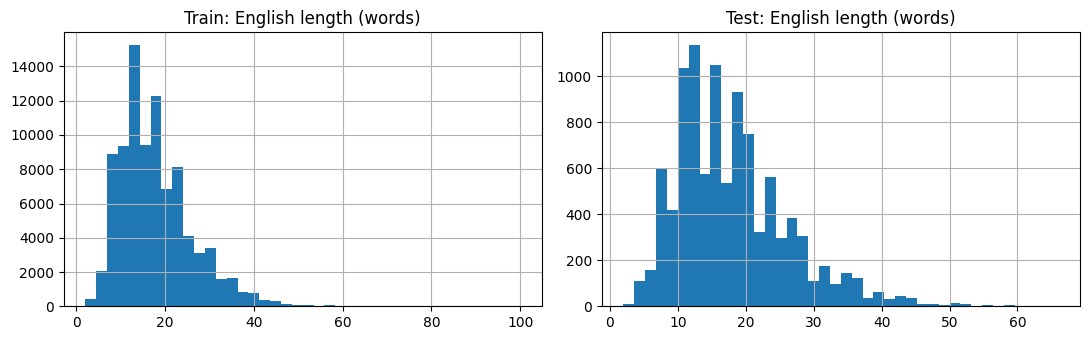

In [7]:
train_parts, dev_parts, test_parts = [], [], []
for b in BINS:
    g = df[df.bin == b].sample(frac=1.0, random_state=SEED)
    if len(g) < 20:
        print(f"WARNING: {b} has only {len(g)} sentences")
    n_test = max(1, int(round(len(g) * TEST_FRAC)))
    test_parts.append(g.iloc[:n_test])
    rest = g.iloc[n_test:]
    n_dev = max(1, int(round(len(rest) * DEV_FRAC)))
    dev_parts.append(rest.iloc[:n_dev])
    train_parts.append(rest.iloc[n_dev:])

train = pd.concat(train_parts).sample(frac=1.0, random_state=SEED).reset_index(drop=True)
dev   = pd.concat(dev_parts).sample(frac=1.0, random_state=SEED).reset_index(drop=True)
test  = pd.concat(test_parts).reset_index(drop=True)

summary = pd.DataFrame({
    "train": train.bin.value_counts(), "dev": dev.bin.value_counts(), "test": test.bin.value_counts()
}).reindex(BINS).fillna(0).astype(int)
summary.loc["total"] = summary.sum()
print(summary)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
train.len.hist(bins=40, ax=ax[0]); ax[0].set_title("Train: English length (words)")
test.len.hist(bins=40, ax=ax[1]);  ax[1].set_title("Test: English length (words)")
plt.tight_layout(); plt.show()

## 7. SentencePiece (trained on the training split only)

In [8]:
import sentencepiece as spm

def dump(lines, path):
    with open(path, "w", encoding="utf-8") as f:
        f.write("\n".join(lines) + "\n")

dump(train.en,  f"{WORK}/train.en");  dump(train.tgt, f"{WORK}/train.tgt")
dump(dev.en,    f"{WORK}/dev.en");    dump(dev.tgt,   f"{WORK}/dev.tgt")
dump(test.en,   f"{WORK}/test.en");   dump(test.tgt,  f"{WORK}/test.tgt")

for name, cov in [("en", 1.0), ("tgt", 0.9995)]:
    spm.SentencePieceTrainer.train(
        input=f"{WORK}/train.{name}", model_prefix=f"{WORK}/spm_{name}",
        vocab_size=SPM_VOCAB, model_type="unigram", character_coverage=cov,
        hard_vocab_limit=False, input_sentence_size=2_000_000, shuffle_input_sentence=True)

sp_en  = spm.SentencePieceProcessor(model_file=f"{WORK}/spm_en.model")
sp_tgt = spm.SentencePieceProcessor(model_file=f"{WORK}/spm_tgt.model")

def encode_file(sp, inp, out):
    lines = open(inp, encoding="utf-8").read().split("\n")[:-1]
    enc = [" ".join(sp.encode(l, out_type=str)) for l in lines]
    dump(enc, out)
    return enc

tr_en  = encode_file(sp_en,  f"{WORK}/train.en",  f"{WORK}/train.sp.en")
tr_tgt = encode_file(sp_tgt, f"{WORK}/train.tgt", f"{WORK}/train.sp.tgt")
encode_file(sp_en,  f"{WORK}/dev.en",   f"{WORK}/dev.sp.en")
encode_file(sp_tgt, f"{WORK}/dev.tgt",  f"{WORK}/dev.sp.tgt")
encode_file(sp_en,  f"{WORK}/test.en",  f"{WORK}/test.sp.en")

# drop over-long training pairs
keep = [i for i in range(len(tr_en)) if len(tr_en[i].split()) <= MAX_SPM_LEN and len(tr_tgt[i].split()) <= MAX_SPM_LEN]
dump([tr_en[i] for i in keep],  f"{WORK}/train.sp.en")
dump([tr_tgt[i] for i in keep], f"{WORK}/train.sp.tgt")
print(f"Training pairs after length filter: {len(keep):,} / {len(tr_en):,}")

I0000 00:00:1792690120.981641      49 sentencepiece_trainer.cc:105] Starts training with : 
trainer_spec {
  input: work/train.en
  input_format: 
  model_prefix: work/spm_en
  model_type: UNIGRAM
  vocab_size: 8000
  self_test_sample_size: 0
  character_coverage: 1
  input_sentence_size: 2000000
  shuffle_input_sentence: 1
  seed_sentencepiece_size: 1000000
  shrinking_factor: 0.75
  max_sentence_length: 4192
  num_threads: 16
  num_sub_iterations: 2
  max_sentencepiece_length: 16
  split_by_unicode_script: 1
  split_by_number: 1
  split_by_whitespace: 1
  split_digits: 0
  pretokenization_delimiter: 
  treat_whitespace_as_suffix: 0
  allow_whitespace_only_pieces: 0
  required_chars: 
  byte_fallback: 0
  vocabulary_output_piece_score: 1
  train_extremely_large_corpus: 0
  seed_sentencepieces_file: 
  hard_vocab_limit: 0
  use_all_vocab: 0
  unk_id: 0
  bos_id: 1
  eos_id: 2
  pad_id: -1
  unk_piece: <unk>
  bos_piece: <s>
  eos_piece: </s>
  pad_piece: <pad>
  unk_surface:  ⁇ 
  enab

Training pairs after length filter: 89,199 / 89,199


## 8. OpenNMT-py config + vocabulary

In [9]:
import yaml

cfg = {
    "save_data": f"{WORK}/onmt_run/example",
    "src_vocab": f"{WORK}/onmt_run/vocab.src",
    "tgt_vocab": f"{WORK}/onmt_run/vocab.tgt",
    "overwrite": True,
    "data": {
        "corpus_1": {"path_src": f"{WORK}/train.sp.en", "path_tgt": f"{WORK}/train.sp.tgt"},
        "valid":    {"path_src": f"{WORK}/dev.sp.en",   "path_tgt": f"{WORK}/dev.sp.tgt"},
    },
    "save_model": f"{WORK}/model/nmt",
    "save_checkpoint_steps": VALID_STEPS,
    "keep_checkpoint": 3,
    "seed": SEED,
    "train_steps": TRAIN_STEPS,
    "valid_steps": VALID_STEPS,
    "warmup_steps": 4000,
    "report_every": 200,
    "early_stopping": 5,

    "world_size": 1,
    "gpu_ranks": [0] if HAS_GPU else [],   # empty list = run on CPU
    "model_dtype": "fp16" if HAS_GPU else "fp32",

    "decoder_type": "transformer", "encoder_type": "transformer",
    "position_encoding": True,
    "enc_layers": 4, "dec_layers": 4, "heads": 8,
    "hidden_size": 256, "word_vec_size": 256, "transformer_ff": 1024,
    "dropout_steps": [0], "dropout": [0.1], "attention_dropout": [0.1],

    "optim": "adam", "adam_beta2": 0.998, "decay_method": "noam",
    "learning_rate": 2.0, "max_grad_norm": 0.0, "label_smoothing": 0.1,
    "param_init": 0.0, "param_init_glorot": True, "normalization": "tokens",
    "batch_type": "tokens", "batch_size": 4096, "valid_batch_size": 2048,
    "accum_count": [2], "accum_steps": [0], "max_generator_batches": 2,
}
os.makedirs(f"{WORK}/onmt_run", exist_ok=True); os.makedirs(f"{WORK}/model", exist_ok=True)
with open(f"{WORK}/config.yaml", "w") as f:
    yaml.safe_dump(cfg, f, sort_keys=False)

!{ONMT}onmt_build_vocab -config {WORK}/config.yaml -n_sample -1

Corpus corpus_1's weight should be given. We default it to 1 for you.
[2026-10-22 17:29:19,485 INFO] Counter vocab from -1 samples.
[2026-10-22 17:29:19,485 INFO] n_sample=-1: Build vocab on full datasets.
[2026-10-22 17:29:22,677 INFO] Counters src: 7996
[2026-10-22 17:29:22,677 INFO] Counters tgt: 8347


## 9. Train

In [10]:
!{ONMT}onmt_train -config {WORK}/config.yaml

[2026-10-22 17:29:25,491 INFO] Missing transforms field for corpus_1 data, set to default: [].
[2026-10-22 17:29:25,491 WARNING] Corpus corpus_1's weight should be given. We default it to 1 for you.
[2026-10-22 17:29:25,491 INFO] Missing transforms field for valid data, set to default: [].
[2026-10-22 17:29:25,491 INFO] Parsed 2 corpora from -data.
[2026-10-22 17:29:25,491 INFO] Get special vocabs from Transforms: {'src': [], 'tgt': []}.
[2026-10-22 17:29:25,519 INFO] The first 10 tokens of the vocabs are:['<unk>', '<blank>', '<s>', '</s>', '▁the', '▁of', '▁.', 's', '▁and', '▁in']
[2026-10-22 17:29:25,519 INFO] The decoder start token is: <s>
[2026-10-22 17:29:25,519 INFO] Building model...
[2026-10-22 17:29:27,656 INFO] Switching model to float32 for amp/apex_amp
[2026-10-22 17:29:27,656 INFO] Non quantized layer compute is fp16
[2026-10-22 17:29:27,910 INFO] NMTModel(
  (encoder): TransformerEncoder(
    (embeddings): Embeddings(
      (make_embedding): Sequential(
        (emb_luts)

## 10. Translate the test set

In [11]:
ckpts = sorted(glob.glob(f"{WORK}/model/nmt_step_*.pt"), key=lambda p: int(p.rsplit("_", 1)[1].split(".")[0]))
best_ckpt = ckpts[-1]
print("Using checkpoint:", best_ckpt)
gpu_flag = "-gpu 0" if HAS_GPU else ""
!{ONMT}onmt_translate -model {best_ckpt} -src {WORK}/test.sp.en -output {WORK}/test.sp.pred {gpu_flag} -beam_size 5 -batch_size 64 -max_length 200

pred_sp = open(f"{WORK}/test.sp.pred", encoding="utf-8").read().split("\n")[:len(test)]
test["hyp"] = [sp_tgt.decode(l.split()) for l in pred_sp]
test[["en", "tgt", "hyp", "len", "bin"]].head()

Using checkpoint: work/model/nmt_step_16000.pt
[2026-10-22 18:06:12,579 INFO] Loading checkpoint from work/model/nmt_step_16000.pt
[2026-10-22 18:06:13,107 INFO] Loading data into the model
[2026-10-22 18:06:50,874 INFO] PRED SCORE: -0.5622, PRED PPL: 1.75 NB SENTENCES: 10114
Time w/o python interpreter load/terminate:  38.323455810546875


,en,tgt,hyp,len,bin
0,6000-7000 kg flowers are obtained from 1 hecta...,એક હેક્ટરમાંથી ૬૦૦૦ - ૭૦૦૦ કિલો ફૂલ મળે છે .,એક હેક્ટર ક્ષેત્રફળથી ૬૦૦૦૦ - ૭૦ કિલો ફૂલ મળે ...,9,bin1
1,At times cancer appears in hairless tumors .,ક્યારેક હાનિરહિત ગાંઠમાં કેન્સર પેદા થઈ જાય છે .,ક્યારેક - ક્યારેક વાળ રહિત ટ્યૂમરમાં કેન્સર દે...,8,bin1
2,Adaptability of cultural environment should be...,સાંસ્કૃતિક વાતાવરણની અનુકૂળતા પર સૌથી વધારે ભા...,સાંસ્કૃતિક વાતાવરણની સમાનતા પર ભાર મૂકવો જોઈએ .,9,bin1
3,Black cardamom makes liver healthy.,મોટી ઈલાયચી લીવરને તંદુરસ્ત બનાવે છે .,મોટી ઈલાયચી કાળજાને સ્વસ્થ બનાવે છે .,5,bin1
4,The news published in the magazines began bein...,પત્રોમાં પ્રકાશિત સમાચારો પર પ્રતિક્રિયા પણ થવ...,પત્ર - પત્રિકાઓમાં પ્રકાશિત સમાચારની ટીકા થવા ...,10,bin1


## 11. Bin-wise BLEU with sacreBLEU

In [12]:
import sacrebleu
from sacrebleu.metrics import BLEU, CHRF

def bleu_obj(tok):
    try:    return BLEU(tokenize=tok)
    except Exception as e:
        print(f"tokenizer '{tok}' unavailable ({e}); skipping"); return None

bleu_13a  = BLEU()                         # default sacreBLEU (13a)
bleu_f200 = bleu_obj("flores200")          # SPM-based; better suited to Indic scripts
chrf      = CHRF(word_order=2)             # chrF++ (extra, robust for Indic)

def score_block(d):
    hyps, refs = d["hyp"].tolist(), [d["tgt"].tolist()]
    r = bleu_13a.corpus_score(hyps, refs)
    row = {"n_sent": len(d), "BLEU(13a)": r.score, "BP": r.bp, "sys_len": r.sys_len, "ref_len": r.ref_len,
           "len_ratio": r.sys_len / max(r.ref_len, 1), "chrF++": chrf.corpus_score(hyps, refs).score}
    if bleu_f200: row["BLEU(flores200)"] = bleu_f200.corpus_score(hyps, refs).score
    return row

rows = {b: score_block(test[test.bin == b]) for b in BINS}
rows["overall"] = score_block(test)
results = pd.DataFrame(rows).T
results.round(2)

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That

,n_sent,BLEU(13a),BP,sys_len,ref_len,len_ratio,chrF++,BLEU(flores200)
bin1,1803.0,19.15,0.87,14598.0,16624.0,0.88,38.11,26.49
bin2,5140.0,15.12,0.86,65894.0,75768.0,0.87,36.18,23.64
bin3,2248.0,12.89,0.87,42073.0,47846.0,0.88,35.04,21.55
bin4,923.0,10.82,0.86,24229.0,27917.0,0.87,32.50,18.56
overall,10114.0,14.07,0.86,146794.0,168155.0,0.87,35.40,22.42


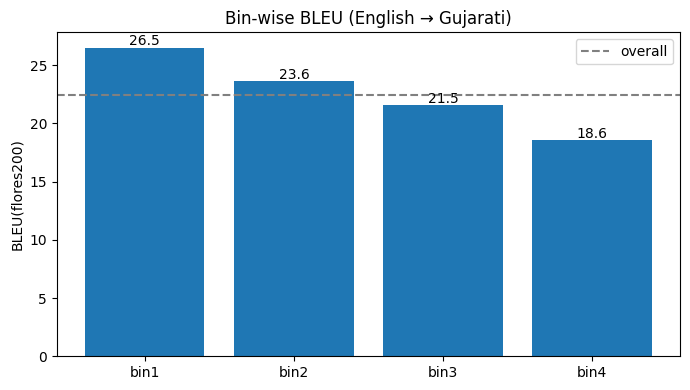

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
col = "BLEU(flores200)" if "BLEU(flores200)" in results else "BLEU(13a)"
vals = results.loc[BINS, col].astype(float)
ax.bar(BINS, vals)
for i, v in enumerate(vals): ax.text(i, v + 0.2, f"{v:.1f}", ha="center")
ax.axhline(float(results.loc["overall", col]), ls="--", c="gray", label="overall")
ax.set_ylabel(col); ax.set_title(f"Bin-wise BLEU (English → {TGT_NAME})"); ax.legend()
plt.tight_layout(); plt.show()

## 12. Analysis helpers

In [14]:
col = "BLEU(13a)"
best, worst = results.loc[BINS, col].astype(float).idxmax(), results.loc[BINS, col].astype(float).idxmin()
print(f"Best bin : {best} ({results.loc[best, col]:.2f} BLEU)")
print(f"Worst bin: {worst} ({results.loc[worst, col]:.2f} BLEU)")
print("\nLength ratio (hyp/ref) and brevity penalty per bin:")
print(results.loc[BINS, ["len_ratio", "BP"]].astype(float).round(3))

print("\nTraining-data share per bin:")
print((train.bin.value_counts(normalize=True).reindex(BINS) * 100).round(1))

# sentence-level view: how does quality move with length?
test["sent_chrf"] = [chrf.sentence_score(h, [r]).score for h, r in zip(test.hyp, test.tgt)]
print("\nMean sentence-level chrF++ per bin:")
print(test.groupby("bin")["sent_chrf"].mean().reindex(BINS).round(2))

# a few examples per bin
pd.set_option("display.max_colwidth", 200)
for b in BINS:
    print(f"\n===== {b} =====")
    for _, r in test[test.bin == b].sample(2, random_state=SEED).iterrows():
        print("SRC:", r.en); print("REF:", r.tgt); print("HYP:", r.hyp); print()

Best bin : bin1 (19.15 BLEU)
Worst bin: bin4 (10.82 BLEU)

Length ratio (hyp/ref) and brevity penalty per bin:
      len_ratio     BP
bin1      0.878  0.870
bin2      0.870  0.861
bin3      0.879  0.872
bin4      0.868  0.859

Training-data share per bin:
bin
bin1    17.8
bin2    50.8
bin3    22.2
bin4     9.1
Name: proportion, dtype: float64

Mean sentence-level chrF++ per bin:
bin
bin1    41.57
bin2    38.42
bin3    35.16
bin4    31.53
Name: sent_chrf, dtype: float64

===== bin1 =====
SRC: To keep skin warm wear thick socks .
REF: પગને ગરમ રાખવા માટે મોટા મોજા પહેરો .
HYP: ચામડી ગરમ રાખવા માટે ગરમ મોજાં પહેરો .

SRC: Innumerous devotees visit these temples .
REF: અસંખ્ય ભક્ત આ મંદિરોના દર્શન કરે છે .
HYP: શ્રદ્ધાળુ આ મંદિરોના દર્શન કરે છે .


===== bin2 =====
SRC: There has been so many investments in the basic facilities during the last 60 years .
REF: પાછલા ૬૦ વર્ષોમાં પ્રાથમિક સુવિધાઓમાં ઘણું રોકાણ થયું છે .
HYP: આધારભૂત સુવિધાઓમાં ગયા ૬૦ વર્ષ દરમિયાન ઘણું રોકાણ થઈ ગયું છે .

SRC:

In [15]:
results.round(3).to_csv(f"{WORK}/binwise_results.csv")
test[["en", "tgt", "hyp", "len", "bin"]].to_csv(f"{WORK}/test_predictions.csv", index=False)
print("Saved binwise_results.csv and test_predictions.csv in", WORK)

Saved binwise_results.csv and test_predictions.csv in work


## 13. Result analysis (fill in after running)

**Setup:** English → Gujarati, ILCI subset of BPCC, Transformer (4+4 layers, d=256) trained with OpenNMT-py, SentencePiece 8k vocab, beam size 5. Bins by English word count: bin1 ≤10, bin2 11–20, bin3 21–29, bin4 ≥30.

**Table:** paste the bin-wise BLEU table from section 11.

**Points to discuss (use your numbers):**
1. **Trend across bins** – does BLEU fall as sentences get longer? Compare bin1 vs bin4 and say how large the gap is.
2. **Brevity penalty / length ratio** – are long-sentence outputs too short (BP < 1)? This indicates truncation or dropped content.
3. **Training-data share** – how many training sentences were in each bin? A bin with little data tends to score worse.
4. **Short sentences** – BLEU on very short sentences is high-variance (one wrong word changes the score a lot) and sentences are often formulaic in ILCI (health/tourism domain).
5. **Qualitative errors** – from the examples: repeated tokens, dropped clauses, wrong named entities, literal translations.
6. **Limitations & improvements** – small data/domain (ILCI), BLEU's weakness on morphologically rich Gujarati (chrF++ as a cross-check), improvements: more data (BPCC-Mined), back-translation, larger model, checkpoint averaging.